# 04.1 Random forest: búsqueda de hiperparámetros (experimento 1)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en `README.md`)

Instrucciones:

- La búsqueda usa Optuna con `N_TRIALS` pruebas y la misma validación en todos los modelos: 5 grupos separados por animal y la semilla `SEED`.
- Nombre de los archivos que se generan: `rf_clf` y `rf_reg`. Es el primer argumento de `tune(...)`, y el notebook de modelado lo usa en `load_best(...)`.
- Se hace con `tune(...)` de `tuning.py`. Solo hay que definir `make_pipe` (el pipeline) y `space` (qué ajustes se prueban y en qué rango).
- En modelos lentos se puede usar `subsample=0.2` (el 20 % de los animales).
- Si cambian las variables o los datos, hay que repetir la búsqueda. El notebook de modelado lo comprueba.
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.pipeline import Pipeline

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, FEATURES, build_preprocessor
from tuning import tune

N_TRIALS = 20
N_TREES = 200

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]

c:\Users\andre\mucsi-deusto-code\machine-learning\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

- `AVAILABLE`: las 22 variables de `dev_features.csv`.
- `FEATURES_EXP1_CLF` y `FEATURES_EXP1_REG`: variables del experimento 1 para este modelo, en clasificación y en regresión.

In [2]:
AVAILABLE = FEATURES
FEATURES_EXP1_CLF = AVAILABLE
FEATURES_EXP1_REG = AVAILABLE

print("El experimento 1 usa estas variables:")
print("Clasificación:", FEATURES_EXP1_CLF)
print("Regresión:", FEATURES_EXP1_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 1 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


## Qué se ajusta

| Ajuste | Qué hace | Rango probado |
|---|---|---|
| `max_depth` | Profundidad máxima de cada árbol. Poca: árboles simples. Mucha: cada árbol se fija en detalles, pero el bosque compensa promediando. | 5 a 40 |
| `min_samples_leaf` | Cuántos animales tiene que haber como mínimo en cada hoja. Pocos: decisiones basadas en casos sueltos. Muchos: decisiones más estables. | 1 a 100 (escala logarítmica) |
| `max_features` | Qué fracción de las variables mira cada árbol en cada pregunta. Poca: árboles más distintos entre sí. Mucha: árboles más parecidos. | 0,05 a 0,6 |
| `class_weight` | Solo en clasificación. `balanced` da más peso a las clases pequeñas, `None` trata a todas igual. | `None` o `balanced` |

El número de árboles (`N_TREES`) no se busca: con más árboles el resultado casi siempre mejora un poco y solo tarda más, así que se fija en 200.

Un bosque tarda bastante más que un árbol solo, así que la búsqueda usa el 20 % de los animales (`subsample=0.2`), como SVM.

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1.

Búsqueda de Random forest (clasificación): 20 pruebas con 12,729 filas y 11,512 animales.
Prueba 1/20: resultado 0.489 | mejor hasta ahora 0.489
Prueba 2/20: resultado 0.503 | mejor hasta ahora 0.503
Prueba 3/20: resultado 0.468 | mejor hasta ahora 0.503
Prueba 4/20: resultado 0.529 | mejor hasta ahora 0.529
Prueba 5/20: resultado 0.523 | mejor hasta ahora 0.529
Prueba 6/20: resultado 0.533 | mejor hasta ahora 0.533
Prueba 7/20: resultado 0.520 | mejor hasta ahora 0.533
Prueba 8/20: resultado 0.518 | mejor hasta ahora 0.533
Prueba 9/20: resultado 0.469 | mejor hasta ahora 0.533
Prueba 10/20: resultado 0.528 | mejor hasta ahora 0.533
Prueba 11/20: resultado 0.533 | mejor hasta ahora 0.533
Prueba 12/20: resultado 0.532 | mejor hasta ahora 0.533
Prueba 13/20: resultado 0.509 | mejor hasta ahora 0.533
Prueba 14/20: resultado 0.529 | mejor hasta ahora 0.533
Prueba 15/20: resultado 0.514 | mejor hasta ahora 0.533
Prueba 16/20: resultado 0.529 | mejor hasta ahora 0.533
Prueba 17/20: resultado

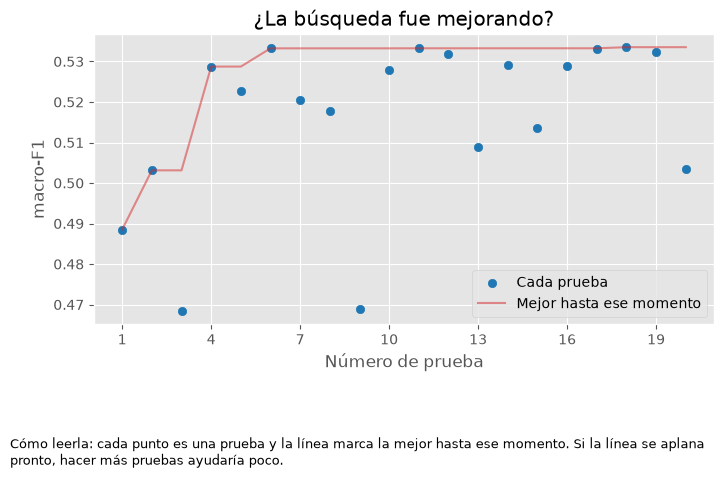

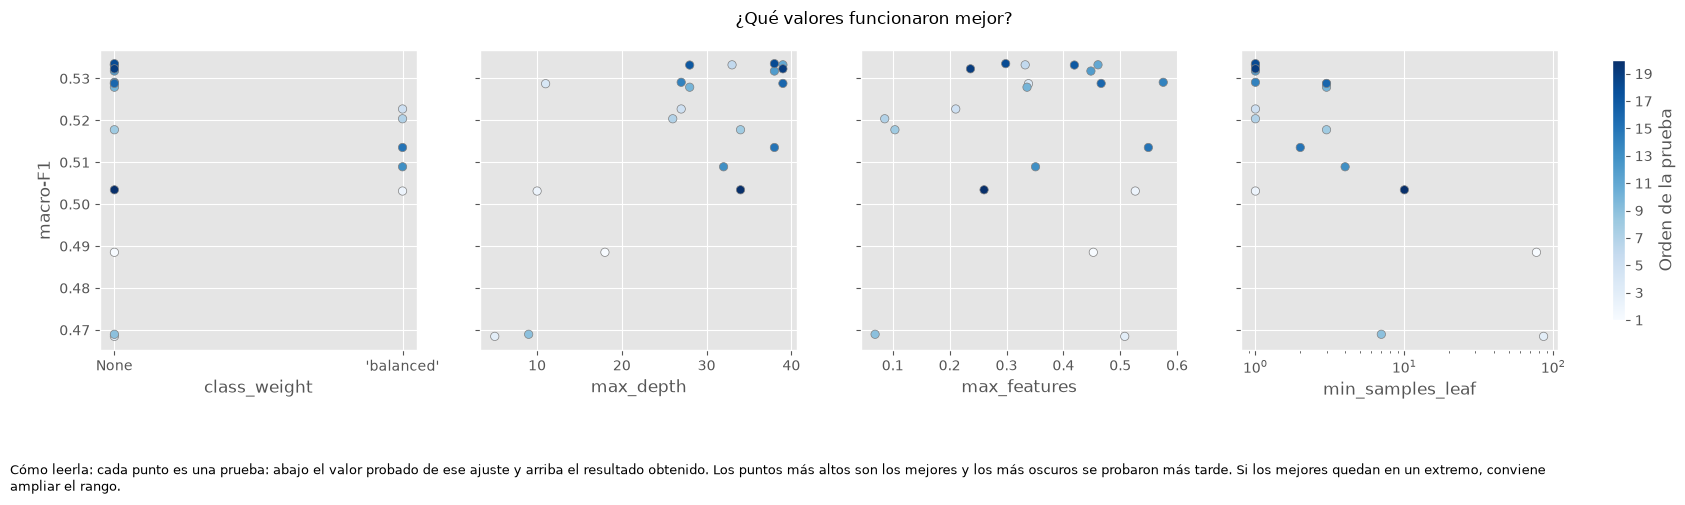

In [3]:
def make_pipe_clf(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_CLF)),
                     ("model", RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=3, **params))])

def space_clf(trial):
    return {"max_depth": trial.suggest_int("max_depth", 5, 40),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 100, log=True),
            "max_features": trial.suggest_float("max_features", 0.05, 0.6),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

PARAMS_HELP = {"max_depth": "Profundidad máxima de cada árbol (alto = más detalle).",
               "min_samples_leaf": "Mínimo de animales en cada decisión final (alto = más estable).",
               "max_features": "Fracción de variables que mira cada árbol en cada pregunta.",
               "class_weight": "balanced da más peso a las clases pequeñas."}

study_clf = tune(
    "rf_clf", make_pipe_clf, space_clf, data[FEATURES_EXP1_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP1_CLF, model_label="Random forest", task_label="clasificación",
    params_help=PARAMS_HELP, n_trials=N_TRIALS, subsample=0.2)

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`. Se elige por R² en log.

Búsqueda de Random forest (regresión): 20 pruebas con 5,392 filas y 4,944 animales.
Prueba 1/20: resultado 0.326 | mejor hasta ahora 0.326
Prueba 2/20: resultado 0.370 | mejor hasta ahora 0.370
Prueba 3/20: resultado 0.335 | mejor hasta ahora 0.370
Prueba 4/20: resultado 0.376 | mejor hasta ahora 0.376
Prueba 5/20: resultado 0.372 | mejor hasta ahora 0.376
Prueba 6/20: resultado 0.380 | mejor hasta ahora 0.380
Prueba 7/20: resultado 0.386 | mejor hasta ahora 0.386
Prueba 8/20: resultado 0.369 | mejor hasta ahora 0.386
Prueba 9/20: resultado 0.311 | mejor hasta ahora 0.386
Prueba 10/20: resultado 0.288 | mejor hasta ahora 0.386
Prueba 11/20: resultado 0.373 | mejor hasta ahora 0.386
Prueba 12/20: resultado 0.383 | mejor hasta ahora 0.386
Prueba 13/20: resultado 0.378 | mejor hasta ahora 0.386
Prueba 14/20: resultado 0.384 | mejor hasta ahora 0.386
Prueba 15/20: resultado 0.380 | mejor hasta ahora 0.386
Prueba 16/20: resultado 0.383 | mejor hasta ahora 0.386
Prueba 17/20: resultado 0.363

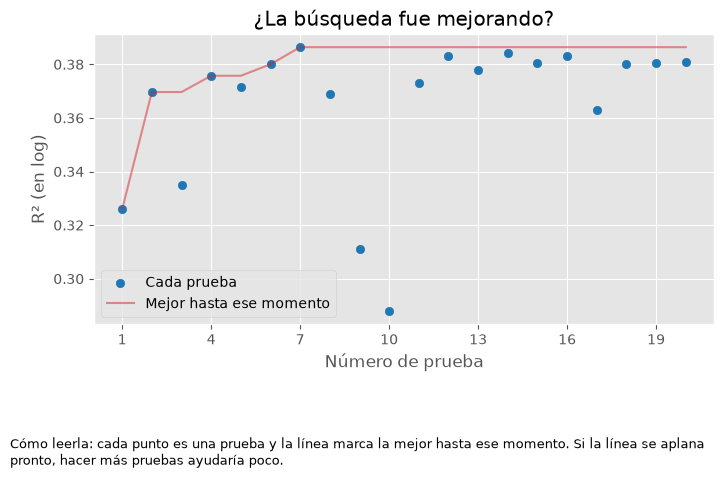

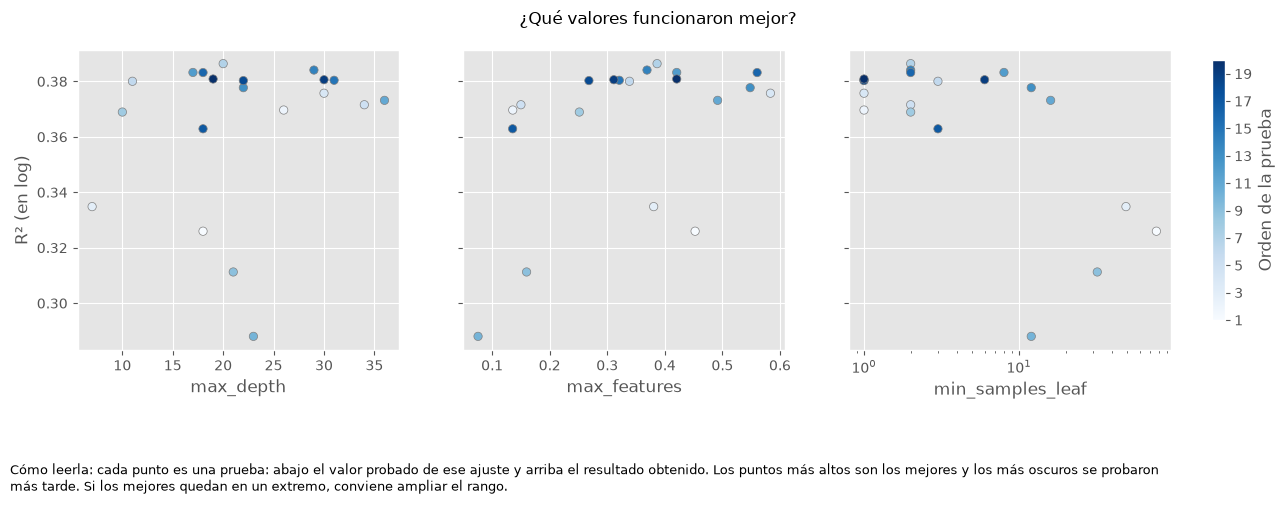

In [4]:
def make_pipe_reg(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_REG)),
                     ("model", RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=3, **params))])

def space_reg(trial):
    return {"max_depth": trial.suggest_int("max_depth", 5, 40),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 100, log=True),
            "max_features": trial.suggest_float("max_features", 0.05, 0.6)}

study_reg = tune(
    "rf_reg", make_pipe_reg, space_reg, data.loc[adopted, FEATURES_EXP1_REG], y_reg, groups_reg,
    scoring="r2", features=FEATURES_EXP1_REG, model_label="Random forest", task_label="regresión",
    params_help=PARAMS_HELP, n_trials=N_TRIALS, subsample=0.2)